# Data Science 3160 project: By Benjamin Hogg & Elijah Stolte
## [Website Link](https://elistolte.github.io)

### Project Goals

Our names are Benjamin Hogg and Elijah Stolte, and we will most likely be studying datasets related to food recalls in the United States.


### Collaboration Plan
For our project, we have created a github repository in which we are both collaborators and will store our project. Within our github repository we will maintain a text file with a to-do list and work division and allocation. We have also exchanged contact information and are planning to meet weekly moving forward to work on the tutorial and stay afloat of project deadlines.

There are a few possible datasets that we want to work with, after some investigation into the links provided on the github page for the project. A few that stood out to us were the following:
1. https://dailyfoodrecalls.com/api/recalls.json
    - This is a dataset that lists every current food recall active in the United States. This is interesting due to the current relevance that food recalls have on our public, most notably with the beef recall happening due to lax foreign import rules.
    - A question that we might want answered from this data set is, "Which recalls are getting more frequent, or which recalls are just a few events (Beef (ongoing), Salmonella (spike))." We could also explore the question, "How exposed is Louisiana to food recalls as of now?"
2. https://open.fda.gov/apis/food/enforcement/
    - This dataset from the FDA reports data from their Recall Enterprise System which contains information on recall events from 2004 to present.
    - Some of this data is similar to the above data but as a historical database, can allow us to answer questions about historical trends such as, "Have beef recalls increased over the past 20 years?"
3. https://huggingface.co/datasets/aungthuhein-dev/betel-leaf
    - This is an interesting dataset, which consists of a villager from Myanmar's handwritten ledger that got transformed into a dataset. It contains 1800+ records from April 2024 to March 2026. The villager sells Betel Leafs, and the dataset covers 3 grades and prices. This is interesting because we can glean a perspective of economics from a region that we don't typically think of in those terms.
    - Some questions that we may want answered from this dataset are, "How do prices reflect economic trends in remote Myanmar?", "How does this villager apply classical western economic ideas to his own products and sales?"
4. https://data.nola.gov/Public-Safety-and-Preparedness/NOPD-Use-of-Force-Incidents/9mnw-mbde/about_data
    - This is a dataset from the nola.gov website that records incidents where the NOPD demonstrated Uses of Force. This is interesting as a local dataset as it is something that we may experience in our day to day lives.
    - Another reason is with New Orleans having a reputation for crime, which trends can we see throughout this dataset? When do incidents become more frequent, and has Use of Force gone up or down throughout the years?
5. https://www.kaggle.com/datasets/alimoh89/tennis-results-and-betting-odds-20142025
    - This is a dataset that has recorded betting lines and tennis results from 2014-2025. This dataset has over 300,000 entries, so we would need to take a slice of matches, maybe a 3-5 year span, or use the kaggle API. Since this dataset also uses ATP, WTA, and Challenger/ITF events, we could just analyze ATP, or WTA, since those are the highest levels of that gender's sport specifically.
    - Some interesting questions to answer from this dataset could be, "Are betting markets accurate with their odds?" "Do the lines hover around a 50% winrate?" "Have these markets become more accurate over time, or lost accuracy?" "Who is most likely to cover?"
6. https://www.kaggle.com/datasets/endrikend/strength-progression-5-8m-sets-10407-lifters
    - This is a dataset about strength progression over time of consistent gym users. It uses workouts from over 10,000 lifters, and has datapoints of each workout from these users. This makes it possible to measure strength over time, such as how long a lifter gets stuck at a certain weight, or where users top out at.
    - Some interesting questions that we could answer using this dataset might be "What is the average duration a lifter tracks their workouts (in months, to study how long people consistently go to the gym for.)" or, "What are the most common plateaus lifters face in different muscle groups/exercises, and how long did it take for them to overcome the plateau on average".

These are just some datasets that I found. Feel free to add more, remove some, or keep as is. We just need 3 by monday.


I am starting the ETL with the food recall dataset. This is by far the smallest dataset I found, and the easiest to ETL for now. We can change this before the deadline, and this is not at all a decision on what we would use. Just the easiest for now.

## Data Source 1

The data comes from the [Daily Food Recalls API](https://dailyfoodrecalls.com/api/recalls.json), a free public JSON feed of every food recall currently active in the US.

In [ ]:
import pandas as pd, requests
recalls = pd.json_normalize(requests.get("https://dailyfoodrecalls.com/api/recalls.json").json()["recalls"])

Show our data shape to see where we need to go from here

In [ ]:
print(recalls.shape)
recalls.head()

(356, 35)


,id,product,brand,company,category,class,classInferred,agency,hazard,hazardType,...,reasonField,score,breaking,firstSeen,slug,state,url,productItems,sources,mergedIds
0,fda-rss-krasnyi-oktyabr-inc-recalls-starfish-s...,Starfish Seafood Trio Because of Possible Heal...,Krasnyi Oktyabr Inc.,Krasnyi Oktyabr Inc.,Food,1,True,FDA,Listeria monocytogenes,pathogen,...,Potential to be contaminated with Listeria mon...,95,True,2026-10-09T21:17:06.681Z,krasnyi-oktyabr-inc-starfish-seafood-trio-beca...,active,https://dailyfoodrecalls.com/recall/krasnyi-ok...,NaN,NaN,NaN
1,fda-rss-gardeners-basics-recalls-waltham-29-br...,Waltham 29 Broccoli Sprouting Seeds Due to Pos...,Gardeners Basics,Gardeners Basics,Food,1,True,FDA,Salmonella,pathogen,...,Product may be contaminated with Salmonella,105,True,2026-10-09T02:47:05.212Z,gardeners-basics-waltham-29-broccoli-sprouting...,active,https://dailyfoodrecalls.com/recall/gardeners-...,NaN,NaN,NaN
2,fda-rss-eden-brothers-recalls-calabrese-brocco...,Calabrese Broccoli Seeds Due to Possible Salmo...,Eden Brothers,Eden Brothers,Food,1,True,FDA,Salmonella,pathogen,...,Potential to be contaminated with Salmonella,105,True,2026-10-08T04:01:51.256Z,eden-brothers-calabrese-broccoli-seeds-due-to-...,active,https://dailyfoodrecalls.com/recall/eden-broth...,NaN,NaN,NaN
3,usda-025-2026,Ineligible Pork Cracklings Products,Inexport Logistics LLC,Inexport Logistics LLC,Meat & Poultry,1,NaN,USDA,Not federally inspected,labeling,...,NaN,72,False,2026-10-03T15:30:05.752Z,inexport-logistics-llc-ineligible-pork-crackli...,active,https://dailyfoodrecalls.com/recall/inexport-l...,[60-g. foil bags of “YUPI GOLPE CON TODO SABOR...,NaN,NaN
4,fda-rss-eak-distribution-llc-recalls-home-grow...,HOME GROWN Green Sprouting Calabrese Broccoli ...,EAK Distribution LLC,EAK Distribution LLC,Food,1,True,FDA,Salmonella,pathogen,...,Potential to be contaminated with Salmonella,105,True,2026-10-03T00:14:33.994Z,eak-distribution-llc-home-grown-green-sproutin...,active,https://dailyfoodrecalls.com/recall/eak-distri...,NaN,NaN,NaN


The raw data has 356 recalls and 35 columns. Many of these are metadata (URL's, internal scores) that don't do anything for us.

We decided to only keep the columns for:
- product & company (who made it and what is it)
- which agency (FDA or USDA)
- class (how bad the health consequences are)
- classInferred (if the website guessed or got it straight from the agency)
- hazard (what the actual problem is)
- allergens (allergens)
- affectedStates (which states the recall affects)
- recall type (voluntary or agency requested)
- recall initiated & report date (when the recall happened and when it was reported)

In [ ]:
# raw data has 35 columns, many are metadata. Only keep relevant
cols = ["product", "company", "agency", "class", "classInferred", "hazard", "hazardType", "allergens", "affectedStates", "recallType", "recallInitiated", "reportDate"]
recalls = recalls[cols].copy()

Here we fix the data types and missing values.

Many columns did not import correctly:
- dates came as plain strings and we need to convert them to datetime.
- class came in as a number but it's actually ordinal.
- hazardtype and agency only have a few possible values, so they become categorical.
- classInferred is only present when the website guessed the recall's class. We need to fill the gaps with False.
- hazard: This is incomplete information that isn't nan, sometimes just said 'see official notice' which is not helpful at all, need to NaN them


In [ ]:
# dates are strings
recalls["recallInitiated"] = pd.to_datetime(recalls["recallInitiated"])
recalls["reportDate"] = pd.to_datetime(recalls["reportDate"])

# class is an ordered severity ranking
recalls["class"] = pd.Categorical(recalls["class"], categories=[1, 2, 3], ordered=True)
recalls["hazardType"] = recalls["hazardType"].astype("category")
recalls["agency"] = recalls["agency"].astype("category")

# classInferred is only present when the site guessed the class
recalls["classInferred"] = recalls["classInferred"].fillna(False).astype(bool)

# placeholder hazards are missing values
recalls["hazard"] = recalls["hazard"].replace(["", "See official notice", "Possible contamination"], pd.NA)

Check our dtypes to make sure we did it correctly.

In [ ]:
# check our dtypes
recalls.dtypes

product                       str
company                       str
agency                   category
class                    category
classInferred                bool
hazard                        str
hazardType               category
allergens                  object
affectedStates             object
recallType                    str
recallInitiated    datetime64[us]
reportDate         datetime64[us]
dtype: object

Check which columns have missing values, should only be hazard which we had to manually replace (classInferred was given falses not nans).

In [ ]:
recalls.isna().sum()

product             0
company             0
agency              0
class               0
classInferred       0
hazard             60
hazardType          0
allergens           0
affectedStates      0
recallType          0
recallInitiated     0
reportDate          0
dtype: int64

Challenges we faced:
- Nested JSON: the data was a json object with metadata around it. Had to pull out the json and flatten it.
- Vague placeholder columns: Didn't figure this out until inspecting the data manually, 60 hazard columns had vague information like 'see official notice' instead of a real hazard, and didn't show up as NaN.
- Inferred values: A lot of recalls had a severity class that was inferred instead of given to them by the FDA/USDA.
- Live data, this is just a snapshot instead of a fixed dataset (no historical data either).

## Data Analysis 1

How severe are current recalls?

208 of the 356 active recalls are Class I, the most dangerous class. Only 19 are Class III. Most recalls currently in effect are serious ones.


In [ ]:
# number of recalls in each severity class (1 = most severe)
severity = recalls.groupby("class", observed=True).agg(count=("product", "size"),inferred=("classInferred", "sum"))
severity["percent"] = (severity["count"] / severity["count"].sum() * 100).round(1)
print(severity)

       count  inferred  percent
class                          
1        208        35     58.4
2        129        53     36.2
3         19         1      5.3


Does type of hazard determine severity?

Almost every pathogen recall (167 of 181) is Class I, while allergen recalls are mostly Class II (66 of 109) and foreign-material recalls are all Class II. The type of hazard largely determines how dangerous a recall is.

In [ ]:
# hazard type vs. severity class: count of recalls in each combination
hazard_by_class = recalls.pivot_table(index="hazardType", columns="class", values="product", aggfunc="count", fill_value=0, observed=True)
hazard_by_class

class,1,2,3
hazardType,,,
allergen,33,66,10
chemical,3,18,7
foreign-material,0,25,0
labeling,5,7,1
pathogen,167,13,1


What are the most common hazards?

Salmonella and listeria show up most often. Undeclared allergens are spread across a bunch of different combinations of foods so it doesn't show up near the top.

In [ ]:
# five most common specific hazards
top_hazards = recalls.groupby("hazard").agg(count=("product", "size")).sort_values("count", ascending=False).head(5)
top_hazards

,count
hazard,
Salmonella,100
Listeria monocytogenes,38
Foreign material,25
"Undeclared milk, tree nuts",18
Undeclared color additive,14


Graph of hazard type by severity class:


Displaying a bar chart to display which hazards correspond to which class. Shows that pathogen related recalls are almost entirely class I while others are mostly class II.

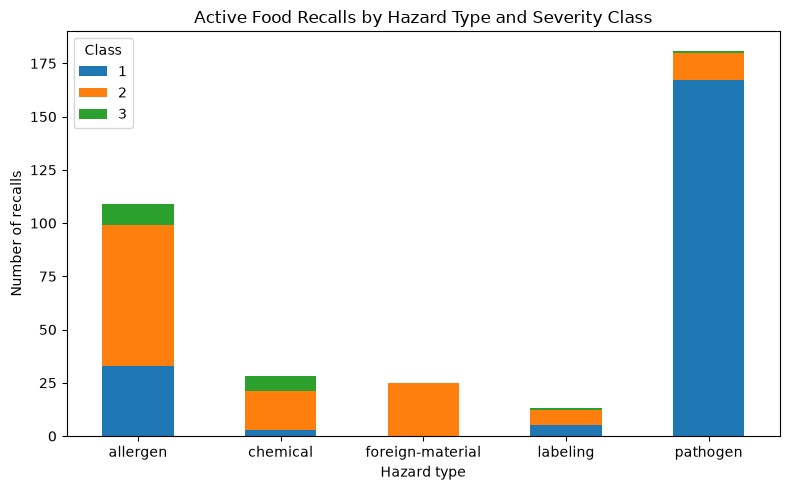

In [ ]:
import matplotlib.pyplot as plt

ax = hazard_by_class.plot(kind="bar", stacked=True, figsize=(8, 5))
ax.set_title("Active Food Recalls by Hazard Type and Severity Class")
ax.set_xlabel("Hazard type")
ax.set_ylabel("Number of recalls")
ax.legend(title="Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Data Source 2

This is the data from the FDA RES (https://open.fda.gov/apis/food/enforcement/) summarizing recall data over time since 2004.

In [ ]:
RES = pd.json_normalize(requests.get("https://dailyfoodrecalls.com/api/recalls.json").json()["recalls"])

### Next steps

We still need to determine which dataset we want to use, and how we would go about using it. We also need to decide what problems to tackle. **Probably need to finish this up as well**


### Export to website

Save the notebook first, then run this cell to export it to `index.html` for our GitHub Pages site.

In [ ]:
# export the saved notebook to index.html (sys.executable makes it use this notebook's Python environment)
import sys
!{sys.executable} -m jupyter nbconvert --to html notebook.ipynb --output index

[NbConvertApp] Converting notebook notebook.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 357761 bytes to index.html
